In [20]:
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = (
    "/Users/marco/Documents/Fall2026/02-courses/"
    "bis-cbb-634/github-repo/dsaa-exercises/patients.xml"
)

tree = ET.parse(file_path)
root = tree.getroot()

records = []

for patient in root.findall("./patients/patient"):
    record = dict(patient.attrib)

    record["diagnoses"] = [
        diagnosis.text.strip()
        for diagnosis in patient.findall("diagnosis")
        if diagnosis.text and diagnosis.text.strip()
    ]

    record["weight_records"] = [
        {
            "value": float(weight.text.strip()),
            "date": weight.get("date"),
            "units": weight.get("units"),
        }
        for weight in patient.findall("./testresults/weight")
        if weight.text and weight.text.strip()
    ]

    records.append(record)

df = pd.DataFrame(records)
df["age"] = pd.to_numeric(df["age"], errors="raise")

display(df)

,age,gender,name,diagnoses,weight_records
0,19.529988,female,Tammy Martin,[],[]
1,1.602197,female,Lucy Stribley,[],[]
2,19.317023,male,Albert Trevino,[],[]
3,79.441208,male,Troy Armour,[],[]
4,71.203863,male,Jose Masseria,[],[]
...,...,...,...,...,...
324352,60.955355,male,Jeremy Brode,[Hypertension],[]
324353,22.676277,female,Lynda Brown,[],[]
324354,64.466378,female,Joyce Adkins,[Hypertension],[]
324355,56.770128,male,Kevin Hensley,[],[]


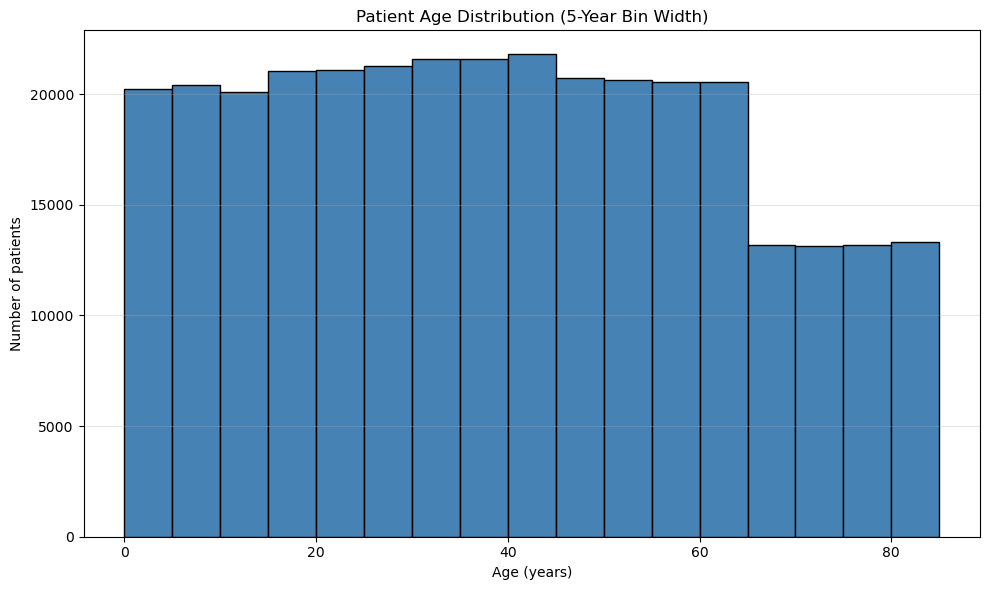

In [14]:
ages = df["age"].dropna()

bin_width = 5
bin_start = np.floor(ages.min() / bin_width) * bin_width
bin_end = (np.floor(ages.max() / bin_width) + 1) * bin_width
bins = np.arange(bin_start, bin_end + bin_width, bin_width)

plt.figure(figsize=(10, 6))
plt.hist(ages, bins=bins, color="steelblue", edgecolor="black")

plt.xlabel("Age (years)")
plt.ylabel("Number of patients")
plt.title("Patient Age Distribution (5-Year Bin Width)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
age_counts = ages.value_counts().sort_index()

duplicate_ages = (
    age_counts[age_counts > 1]
    .rename_axis("age")
    .reset_index(name="patient_count")
)

print("Any exact duplicate ages:", not duplicate_ages.empty)
print("Number of distinct ages shared by patients:", len(duplicate_ages))
print(
    "Total patients with a shared age:",
    int(duplicate_ages["patient_count"].sum())
)


Any exact duplicate ages: False
Number of distinct ages shared by patients: 0
Total patients with a shared age: 0


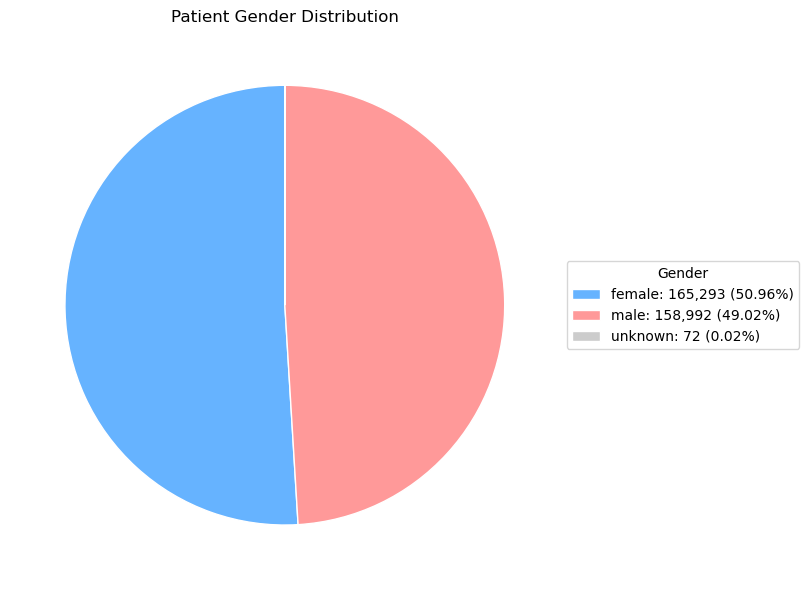

In [23]:
gender_counts = df["gender"].value_counts()

labels = [
    f"{gender}: {count:,} ({count / gender_counts.sum():.2%})"
    for gender, count in gender_counts.items()
]

fig, ax = plt.subplots(figsize=(8, 6))

wedges, _ = ax.pie(
    gender_counts,
    startangle=90,
    colors=["#66b3ff", "#ff9999", "#cccccc"],
    wedgeprops={"edgecolor": "white"}
)

ax.legend(
    wedges,
    labels,
    title="Gender",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set_title("Patient Gender Distribution")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [27]:
# Convert the DataFrame into a list of patient records
patients = df.to_dict(orient="records")

# Sort records by age in ascending order
sorted_patients = sorted(patients, key=lambda patient: patient["age"])

# The last record contains the oldest patient
oldest_patient = sorted_patients[-1]

print("Oldest patient:")
print("Name:", oldest_patient["name"])
print("Age:", oldest_patient["age"])
print("Gender:", oldest_patient["gender"])

display(pd.DataFrame(sorted_patients[-5:]))

Oldest patient:
Name: Monica Caponera
Age: 84.99855742449432
Gender: female


,age,gender,name,diagnoses,weight_records
0,84.997240,male,Stephan Yeargin,[Hypertension],[]
1,84.997943,male,Michael Ali,[],[]
2,84.998202,female,Tracy Walker,[Hypertension],[]
3,84.998293,male,Raymond Leigh,[],[]
4,84.998557,female,Monica Caponera,[Hypertension],[]


In [25]:
top_two = [None, None]

for i in range(len(patients)):
    current = patients[i]

    if top_two[0] is None or current["age"] > top_two[0]["age"]:
        top_two[1] = top_two[0]
        top_two[0] = current
    elif top_two[1] is None or current["age"] > top_two[1]["age"]:
        top_two[1] = current

display(pd.DataFrame(top_two, index=["Oldest", "Second oldest"]))

,age,gender,name,diagnoses,weight_records
Oldest,84.998557,female,Monica Caponera,[Hypertension],[]
Second oldest,84.998293,male,Raymond Leigh,[],[]


In [30]:
def binary_search_left(patients, target_age):
    left = 0
    right = len(patients)

    while left < right:
        mid = (left + right) // 2

        if patients[mid]["age"] < target_age:
            left = mid + 1
        else:
            right = mid

    return left

def binary_search_right(patients, target_age):
    left = 0
    right = len(patients)

    while left < right:
        mid = (left + right) // 2

        if patients[mid]["age"] <= target_age:
            left = mid + 1
        else:
            right = mid

    return left

target_age = 41.5

left_index = binary_search_left(sorted_patients, target_age)
right_index = binary_search_right(sorted_patients, target_age)

matching_patients = sorted_patients[left_index:right_index]

print("Matching patients:", len(matching_patients))
display(pd.DataFrame(matching_patients))

Matching patients: 1


,age,gender,name,diagnoses,weight_records
0,41.5,male,John Braswell,[],[]


In [31]:
count_at_least_target = len(sorted_patients) - left_index

print(f"Patients aged at least {target_age}: {count_at_least_target}")

Patients aged at least 41.5: 150471
